In [1]:
# 05 - The benchmark of our 5 models -> ONNX (for Service 3: audio_engine)
#
# The project: the audio engine runs the benchmark of our 5 models (TP4 decision tree, TP3 SVM, TP7 CNN, TP8 ResNet50
# transfer learning, Transformer-CNN) with ONNX Runtime, and the official answer is the model with the best mean
# VALIDATION RECALL (it misses the fewest sick hearts); the test results are shown next to it.
# ONNX = 1 small file per model, that the container runs fast without TensorFlow or scikit-learn.
#
# 1. MLflow (experiment audio_benchmark_final): the best run of each model, sorted by validation recall
# 2. the benchmark figure: validation and test recall / F1 of every model
# 3. export each model to ONNX (the best one also as cardio_model.onnx) and check that ONNX gives the same answers
# 4. benchmark.json = the list of our models and their scores, for the audio engine
# 5. MLflow: the Model Registry (cardio_model, alias "champion") + the ONNX files in the runs

In [2]:
# The first time only: the tools to export to ONNX and to run an ONNX model. Then click "Restart" (the kernel).
%pip install tf2onnx==1.17.0 onnx==1.23.2 onnxruntime==1.23.2 skl2onnx==1.20.0

Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'D:\MLOps_Project\venv\Scripts\python.exe -m pip install --upgrade pip' command.


In [3]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"    # hide the TensorFlow info messages

import gc
import json
import pickle
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
import IPython.display as ipd

import keras
from keras.layers import Input, Resizing, Lambda
from keras.applications.resnet50 import preprocess_input as resnet_preprocess
import mlflow
import mlflow.keras
import mlflow.sklearn
from mlflow.tracking import MlflowClient
import onnxruntime as ort
from skl2onnx import to_onnx    # scikit-learn model -> ONNX (for the SVM and the tree)

In [4]:
# my folders
project_folder = "D:/MLOps_Project/"
ourdataset_folder = "D:/MLOps_Project/ourdataset/train/"
plots_folder = "D:/MLOps_Project/models plots/"
engine_folder = "D:/MLOps_Project/audio_engine/"    # the folder of Service 3 (the audio engine)
os.makedirs(engine_folder, exist_ok=True)


def load_data(file_name):
    with open(file_name, "rb") as f:
        return pickle.load(f)


# MLflow: the container must be running (docker compose up -d mlflow-server)
mlflow.set_tracking_uri("http://localhost:5000")
mlflow.set_experiment("audio_benchmark_final")

<Experiment: artifact_location='mlflow-artifacts:/2', creation_time=1795720788693, experiment_id='2', last_update_time=1795720788693, lifecycle_stage='active', name='audio_benchmark_final', tags={}>

In [5]:
# ==================== 1. The benchmark: the best run of each model, from MLflow ====================
runs = mlflow.search_runs(experiment_names=["audio_benchmark_final"])

# the final runs: a saved model + validation (mean_*) and test (test_*) metrics
# (the ensemble of notebook 08 has no model file: it is the mean of the probabilities of its members)
has_model = runs["tags.mlflow.log-model.history"].notna() | (runs["params.model"] == "Ensemble")
runs = runs[has_model & runs["metrics.mean_recall"].notna() & runs["metrics.test_recall"].notna()]
if "tags.superseded" in runs.columns:
    runs = runs[runs["tags.superseded"].isna()]    # a run replaced by a newer version of its notebook (kept as history)

# the best run of each model = the highest mean validation recall (if equal: the highest mean validation F1)
runs = runs.sort_values(["metrics.mean_recall", "metrics.mean_f1"], ascending=False)
all_best_runs = runs.drop_duplicates("params.model")    # 1 run per model (VGG16 included, to compare)

columns = ["tags.mlflow.runName", "params.model", "metrics.mean_recall", "metrics.mean_f1", "metrics.mean_precision",
           "metrics.mean_accuracy", "metrics.test_recall", "metrics.test_f1", "metrics.test_auc"]
ipd.display(all_best_runs[columns].round(3))

# the 5 models of the audio engine + the ensemble: VGG16 stays in MLflow only (ResNet50 is our transfer-learning model)
ENGINE_MODELS = ["DecisionTree", "SVM", "CNN", "ResNet50", "TransformerCNN", "Ensemble"]
best_runs = all_best_runs[all_best_runs["params.model"].isin(ENGINE_MODELS)].reset_index(drop=True)
assert len(best_runs) == 6, "a model is missing in audio_benchmark_final: run its notebook (02, 03, 04, 06, 07, 08)"
print("The best model (the official answer of the audio engine):", best_runs.loc[0, "params.model"])

,tags.mlflow.runName,params.model,metrics.mean_recall,metrics.mean_f1,metrics.mean_precision,metrics.mean_accuracy,metrics.test_recall,metrics.test_f1,metrics.test_auc
47,cnn,CNN,0.938,0.628,0.472,0.750,0.909,0.661,0.932
12,svm_rbf_extended72,SVM,0.894,0.705,0.582,0.832,0.915,0.728,0.944
0,ensemble,Ensemble,0.858,0.714,0.619,0.843,0.933,0.726,0.954
48,decision_tree_entropy_depth7,DecisionTree,0.820,0.657,0.550,0.807,0.927,0.643,0.891
33,transformer_cnn,TransformerCNN,0.815,0.658,0.598,0.809,0.861,0.684,0.933
8,resnet50,ResNet50,0.793,0.746,0.704,0.879,0.812,0.764,0.955
4,vgg16,VGG16,0.784,0.721,0.669,0.864,0.764,0.716,0.936


The best model (the official answer of the audio engine): CNN


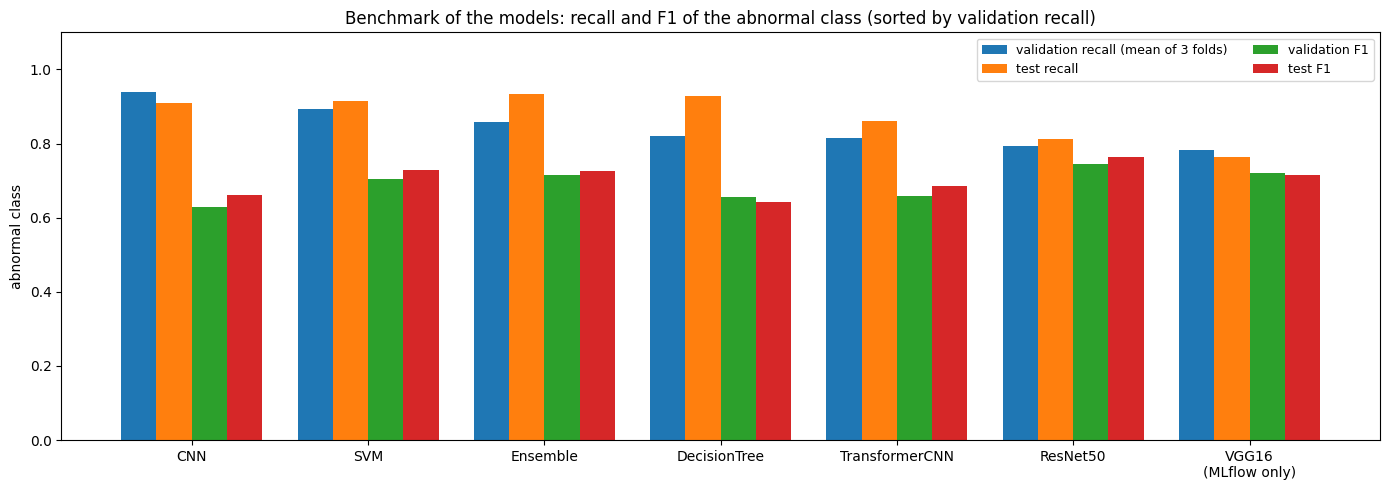

In [6]:
# ==================== 2. The benchmark figure: validation (3 folds) and test (20%) of every model ====================
plt.figure(figsize=(14, 5))
names = list(all_best_runs["params.model"])
x = np.arange(len(names))
plt.bar(x - 0.3, all_best_runs["metrics.mean_recall"], width=0.2, label="validation recall (mean of 3 folds)")
plt.bar(x - 0.1, all_best_runs["metrics.test_recall"], width=0.2, label="test recall")
plt.bar(x + 0.1, all_best_runs["metrics.mean_f1"], width=0.2, label="validation F1")
plt.bar(x + 0.3, all_best_runs["metrics.test_f1"], width=0.2, label="test F1")
labels = []
for name in names:
    if name in ENGINE_MODELS:
        labels.append(name)
    else:
        labels.append(name + "\n(MLflow only)")
plt.xticks(x, labels)
plt.ylim(0, 1.1)
plt.ylabel("abnormal class")
plt.title("Benchmark of the models: recall and F1 of the abnormal class (sorted by validation recall)")
plt.legend(loc="upper right", ncol=2, fontsize=9)
plt.tight_layout()
plt.savefig(plots_folder + "benchmark_comparison.png")
plt.show()

In [7]:
# ==================== 3. Export each model to ONNX, and check that ONNX gives the same answers ====================
# The check uses 20 wavs of the test set: the features are made here with the SAME functions as the audio engine,
# then the original model and its ONNX version must give the same class and (almost) the same probability.
SR = 2000
with open(project_folder + "splits/test_files.json") as f:
    split = json.load(f)
check_files = []
for name in split["test_files"][:20]:
    if os.path.exists(ourdataset_folder + "abnormal/" + name):
        check_files.append(ourdataset_folder + "abnormal/" + name)
    else:
        check_files.append(ourdataset_folder + "normal/" + name)
check_signals = [librosa.load(file, sr=SR)[0] for file in check_files]


def cut(signal, seconds):
    # the same duration for every wav (like in the notebooks): the middle part, a shorter wav is repeated
    n = SR * seconds
    if len(signal) < n:
        return np.tile(signal, n // len(signal) + 1)[:n]
    start = (len(signal) - n) // 2
    return signal[start:start + n]


def signaltonoise(a, axis=0, ddof=0):
    a = np.asanyarray(a)
    m = a.mean(axis)
    sd = a.std(axis=axis, ddof=ddof)
    return np.where(sd == 0, 0, m / sd)


# the features of each model = the SAME code as in its notebook (and in audio_engine/main.py)
def features_mfcc(signal):
    # TP4: 13 MFCC on the middle 5 s -> the mean and the std of each one = 26 numbers
    mfcc = librosa.feature.mfcc(y=cut(signal, 5), sr=SR, n_mfcc=13, n_fft=256, hop_length=128, n_mels=30)
    return list(np.mean(mfcc, axis=1)) + list(np.std(mfcc, axis=1))


def features_extended(signal):
    # Zaineb's 72 features on the whole wav (notebooks 02 and 03)
    duration = len(signal) / SR
    snr = float(signaltonoise(signal / max(np.max(np.abs(signal)), 1e-10)))
    S = librosa.feature.melspectrogram(y=signal, sr=SR, n_fft=512, hop_length=128, n_mels=20)
    S_DB = librosa.power_to_db(S, ref=np.max)
    mfcc = librosa.feature.mfcc(y=signal, sr=SR, n_mfcc=13, n_fft=512, hop_length=128, n_mels=20)
    centroid = librosa.feature.spectral_centroid(y=signal, sr=SR, n_fft=512, hop_length=128)
    zcr = librosa.feature.zero_crossing_rate(signal, frame_length=512, hop_length=128)
    return ([duration, snr] + list(np.mean(S_DB, axis=1)) + list(np.std(S_DB, axis=1))
            + list(np.mean(mfcc, axis=1)) + list(np.std(mfcc, axis=1))
            + [np.mean(centroid), np.std(centroid), np.mean(zcr), np.std(zcr)])


def features_mel_flat(signal, seconds):
    # TP3: Mel spectrogram of 30 bands, flattened
    S = librosa.feature.melspectrogram(y=cut(signal, seconds), sr=SR, n_fft=256, hop_length=256, n_mels=30)
    return librosa.power_to_db(S, ref=np.max).flatten()


def spectrogram_40x157(signal):
    # TP7: Mel spectrogram of 40 bands on the middle 5 s, values from 0 to 1 -> (40, 157)
    S = librosa.feature.melspectrogram(y=cut(signal, 5), sr=SR, n_fft=256, hop_length=64, n_mels=40)
    return (librosa.power_to_db(S, ref=np.max) + 80) / 80


# the colours of plt.cm.magma, as a table of 256 colours (red, green, blue): the audio engine has no matplotlib
magma_lut = plt.cm.magma(np.arange(256))[:, :3]
np.save(engine_folder + "magma_lut.npy", magma_lut)


def magma_image(spectrogram):
    # the same thing as plt.cm.magma(x)[..., :3] * 255 (notebook 06), with the table: colour number = int(x * 256)
    index = np.minimum((spectrogram * 256).astype(int), 255)
    return magma_lut[index] * 255                          # (40, 157, 3), colours from 0 to 255


# the check of the table: the same colours as matplotlib for real spectrograms
for signal in check_signals[:5]:
    S = spectrogram_40x157(signal)
    assert np.allclose(magma_image(S), plt.cm.magma(S)[..., :3] * 255), "the magma table is not the same as matplotlib"
print("magma_lut.npy: the same colours as plt.cm.magma")


def model_input(model_name, features_text, seconds, signals):
    # the input of each model for a list of signals (float32: the type ONNX wants)
    rows = []
    for signal in signals:
        if model_name in ["DecisionTree", "SVM"] and "extended" in features_text:
            rows.append(features_extended(signal))
        elif model_name == "DecisionTree":
            rows.append(features_mfcc(signal))
        elif model_name == "SVM":
            rows.append(features_mel_flat(signal, int(seconds)))
        elif model_name in ["CNN", "TransformerCNN"]:
            rows.append(spectrogram_40x157(signal).reshape(40, 157, 1))
        else:    # ResNet50: the magma image (the resize and preprocess_input are inside the ONNX model)
            rows.append(magma_image(spectrogram_40x157(signal)))
    return np.array(rows).astype("float32")

magma_lut.npy: the same colours as plt.cm.magma


In [8]:
# ResNet50: the MLflow model takes the image ALREADY resized to 224 x 224 and prepared by preprocess_input.
# For the engine (no TensorFlow), we put these 2 steps INSIDE the model before exporting it (Zaineb's idea):
#   magma image 40 x 157 x 3 (0-255) -> Resizing(224, 224) (bilinear, like tf.image.resize) -> preprocess_input -> model
def resnet_with_preprocessing(mlflow_model):
    image = Input(shape=(40, 157, 3))
    x = Resizing(224, 224, interpolation="bilinear")(image)
    x = Lambda(resnet_preprocess)(x)        # RGB -> BGR and minus the mean ImageNet colour (like notebook 06)
    # training=False: the Dropout and BatchNormalization layers always work in "prediction" mode in the exported model
    # (without it, the Dropout of the classifier was exported with a random number generator that ONNX refuses)
    return keras.Model(image, mlflow_model(x, training=False))


def notebook06_probability(mlflow_model, signals):
    # the exact preparation of notebook 06 (matplotlib + tf.image.resize + preprocess_input), to compare
    import tensorflow as tf
    S = np.array([spectrogram_40x157(signal) for signal in signals])
    images = plt.cm.magma(S)[..., :3] * 255
    images = tf.image.resize(images, (224, 224)).numpy()
    return mlflow_model.predict(resnet_preprocess(images), verbose=0).ravel()

In [9]:
models = []    # the information of each model, for benchmark.json
for i in range(len(best_runs)):
    run = best_runs.iloc[i]
    name = run["params.model"]
    features_text = run["params.features"]
    seconds = run["params.seconds"] if isinstance(run["params.seconds"], str) else "5"
    file_name = name.lower() + ".onnx"
    if name == "Ensemble":
        # no ONNX file: the engine averages the probabilities of the members (their ONNX files are made here)
        models.append({"model": "Ensemble", "file": None, "members": run["params.members"].split(","),
                       "features": features_text, "seconds": "5",
                       "recall": round(float(run["metrics.mean_recall"]), 3),
                       "precision": round(float(run["metrics.mean_precision"]), 3),
                       "f1": round(float(run["metrics.mean_f1"]), 3),
                       "accuracy": round(float(run["metrics.mean_accuracy"]), 3),
                       "auc": round(float(run["metrics.mean_auc"]), 3),
                       "test_recall": round(float(run["metrics.test_recall"]), 3),
                       "test_precision": round(float(run["metrics.test_precision"]), 3),
                       "test_f1": round(float(run["metrics.test_f1"]), 3),
                       "test_accuracy": round(float(run["metrics.test_accuracy"]), 3),
                       "test_auc": round(float(run["metrics.test_auc"]), 3),
                       "mlflow_run_id": run["run_id"]})
        print("Ensemble = the mean of", run["params.members"], "(no file)")
        continue
    X = model_input(name, features_text, seconds, check_signals)

    if name in ["DecisionTree", "SVM"]:
        model = mlflow.sklearn.load_model("runs:/" + run["run_id"] + "/model")
        y_model = model.predict(X)
        onnx_model = to_onnx(model, X[:1])                                # scikit-learn -> ONNX (skl2onnx)
        with open(engine_folder + file_name, "wb") as f:
            f.write(onnx_model.SerializeToString())
        p_model = None
    else:
        model = mlflow.keras.load_model("runs:/" + run["run_id"] + "/model")
        if name == "ResNet50":
            p_original = notebook06_probability(model, check_signals)    # the original way (notebook 06)
            model = resnet_with_preprocessing(model)
        p_model = model.predict(X, verbose=0).ravel()                    # predict once before exporting (tf2onnx)
        y_model = (p_model > 0.5).astype(int)
        model.export(engine_folder + file_name, format="onnx")          # Keras -> ONNX (it uses tf2onnx)

    # check with ONNX Runtime (what the container uses): the same decision and the same probability?
    session = ort.InferenceSession(engine_folder + file_name)
    outputs = session.run(None, {session.get_inputs()[0].name: X})
    if p_model is None:
        y_onnx = outputs[0]                                 # the SVM and the tree give the class (0 or 1)
        print(name, "->", file_name, "| same decision for", np.sum(y_model == y_onnx), "of", len(X), "wavs")
        assert np.all(y_model == y_onnx)
    else:
        p_onnx = outputs[0].ravel()                         # the probability of "abnormal"
        difference = np.max(np.abs(p_model - p_onnx))
        print(name, "->", file_name, "| same decision for", np.sum(y_model == (p_onnx > 0.5)), "of", len(X),
              "wavs | max difference of probability = {:.1e}".format(difference))
        assert np.all(y_model == (p_onnx > 0.5)) and difference < 1e-4
        if name == "ResNet50":
            difference = np.max(np.abs(p_original - p_onnx))
            print("   ResNet50 ONNX vs notebook 06 (matplotlib + TensorFlow): max difference = {:.1e}".format(difference))
            assert difference < 1e-4
    print("   size: {:.1f} MB".format(os.path.getsize(engine_folder + file_name) / 1024**2))
    # free the memory of this model before the next one (the ResNet50 export needs several GB of RAM)
    del model
    keras.backend.clear_session()
    gc.collect()

    models.append({
        "model": name,
        "file": file_name,
        "features": features_text,
        "seconds": seconds,
        "recall": round(float(run["metrics.mean_recall"]), 3),            # validation: the mean of the 3 folds
        "precision": round(float(run["metrics.mean_precision"]), 3),
        "f1": round(float(run["metrics.mean_f1"]), 3),
        "accuracy": round(float(run["metrics.mean_accuracy"]), 3),
        "auc": round(float(run["metrics.mean_auc"]), 3),
        "test_recall": round(float(run["metrics.test_recall"]), 3),       # test: the final model on the 20% test set
        "test_precision": round(float(run["metrics.test_precision"]), 3),
        "test_f1": round(float(run["metrics.test_f1"]), 3),
        "test_accuracy": round(float(run["metrics.test_accuracy"]), 3),
        "test_auc": round(float(run["metrics.test_auc"]), 3),
        "mlflow_run_id": run["run_id"],
    })

# the best model with a file (validation recall) gets the name asked in the project: cardio_model.onnx
best_single = None
for m in models:
    if m["file"] is not None and best_single is None:
        best_single = m
shutil.copy(engine_folder + best_single["file"], engine_folder + "cardio_model.onnx")
print("cardio_model.onnx = the", best_single["model"])

Saved artifact at 'D:/MLOps_Project/audio_engine/cnn.onnx'.


CNN -> cnn.onnx | same decision for 20 of 20 wavs | max difference of probability = 1.8e-07
   size: 0.5 MB


SVM -> svm.onnx | same decision for 20 of 20 wavs
   size: 0.4 MB
Ensemble = the mean of CNN,ResNet50,TransformerCNN,DecisionTree (no file)


DecisionTree -> decisiontree.onnx | same decision for 20 of 20 wavs
   size: 0.0 MB


Saved artifact at 'D:/MLOps_Project/audio_engine/transformercnn.onnx'.


TransformerCNN -> transformercnn.onnx | same decision for 20 of 20 wavs | max difference of probability = 4.8e-07
   size: 0.4 MB


Saved artifact at 'D:/MLOps_Project/audio_engine/resnet50.onnx'.


ResNet50 -> resnet50.onnx | same decision for 20 of 20 wavs | max difference of probability = 2.2e-06
   ResNet50 ONNX vs notebook 06 (matplotlib + TensorFlow): max difference = 2.2e-06
   size: 91.6 MB


cardio_model.onnx = the CNN


In [10]:
# ==================== 4. benchmark.json: the models of the audio engine, the best one first ====================
benchmark = {
    "best_model": models[0]["model"],
    "selection": "highest mean validation recall of abnormal (3 folds of the 80% train part), then F1",
    "models": models,
}
with open(engine_folder + "benchmark.json", "w") as f:
    json.dump(benchmark, f, indent=4)
ipd.display(pd.DataFrame(models).drop(columns=["mlflow_run_id"]))

,model,file,features,seconds,recall,precision,f1,accuracy,auc,test_recall,test_precision,test_f1,test_accuracy,test_auc,members
0,CNN,cnn.onnx,"mel spectrogram 40 x 157 (5 s, 2000 Hz)",5,0.938,0.472,0.628,0.750,0.905,0.909,0.519,0.661,0.791,0.932,NaN
1,SVM,svm.onnx,extended features (72),whole wav,0.894,0.582,0.705,0.832,0.931,0.915,0.604,0.728,0.847,0.944,NaN
2,Ensemble,None,soft vote: mean of the probabilities of CNN + ...,5,0.858,0.619,0.714,0.843,0.941,0.933,0.595,0.726,0.843,0.954,"[CNN, ResNet50, TransformerCNN, DecisionTree]"
3,DecisionTree,decisiontree.onnx,extended features (72),whole wav,0.820,0.550,0.657,0.807,0.864,0.927,0.492,0.643,0.769,0.891,NaN
4,TransformerCNN,transformercnn.onnx,"mel spectrogram 40 x 157 (5 s, 2000 Hz)",5,0.815,0.598,0.658,0.809,0.927,0.861,0.568,0.684,0.822,0.933,NaN
5,ResNet50,resnet50.onnx,mel spectrogram 40 x 157 -> magma image 224 x ...,5,0.793,0.704,0.746,0.879,0.942,0.812,0.720,0.764,0.887,0.955,NaN


In [11]:
# ==================== 5. MLflow ====================
# the Model Registry = the shelf of our "official" models: the best model is saved as "cardio_model" (version 1, 2, ...)
# and gets the alias "champion" (the version that the platform should use)
# (the model file of the best model with a file: the ensemble has no file of its own)
version = mlflow.register_model("runs:/" + best_single["mlflow_run_id"] + "/model", "cardio_model")
client = MlflowClient()
client.set_registered_model_alias("cardio_model", "champion", version.version)
client.set_model_version_tag("cardio_model", version.version, "model", best_single["model"])
print("cardio_model version", version.version, "=", best_single["model"], "-> alias champion")

# each ONNX file goes in the run of its model (next to the original model), except the big ResNet50 file (~95 MB)
for m in models:
    if m["file"] is None:
        continue
    with mlflow.start_run(run_id=m["mlflow_run_id"]):
        if os.path.getsize(engine_folder + m["file"]) < 50 * 1024**2:
            mlflow.log_artifact(engine_folder + m["file"], artifact_path="onnx")
with mlflow.start_run(run_id=models[0]["mlflow_run_id"]):
    mlflow.log_artifact(engine_folder + "benchmark.json")
    mlflow.log_artifact(plots_folder + "benchmark_comparison.png", artifact_path="plots")

Registered model 'cardio_model' already exists. Creating a new version of this model...


2026/11/27 14:40:44 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: cardio_model, version 5


Created version '5' of model 'cardio_model'.


cardio_model version 5 = CNN -> alias champion


🏃 View run cnn at: http://localhost:5000/#/experiments/2/runs/d4e6661bed084af79cfee5d2f1f791cd
🧪 View experiment at: http://localhost:5000/#/experiments/2


🏃 View run svm_rbf_extended72 at: http://localhost:5000/#/experiments/2/runs/1dacb5eb4b8a4746b09e6d438e2a99e4
🧪 View experiment at: http://localhost:5000/#/experiments/2


🏃 View run decision_tree_entropy_depth7 at: http://localhost:5000/#/experiments/2/runs/4e923eb6034d4398a240b628681dd110
🧪 View experiment at: http://localhost:5000/#/experiments/2


🏃 View run transformer_cnn at: http://localhost:5000/#/experiments/2/runs/da3bc84996f54efd8e61960772119cbb
🧪 View experiment at: http://localhost:5000/#/experiments/2


🏃 View run resnet50 at: http://localhost:5000/#/experiments/2/runs/c4951b31b36c492ea483efcaa6afe0fe
🧪 View experiment at: http://localhost:5000/#/experiments/2


🏃 View run cnn at: http://localhost:5000/#/experiments/2/runs/d4e6661bed084af79cfee5d2f1f791cd
🧪 View experiment at: http://localhost:5000/#/experiments/2
